In [76]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np, pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline

In [ ]:
PATHFILE = r"..\data\raw\cs-training.csv"
train_df = pd.read_csv(PATHFILE, index_col=0)

target_name = 'SeriousDlqin2yrs'
features_name = train_df.drop(target_name, axis=1).columns

train_df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [212]:
# Missing Data: MonthlyIncome, NumberOfDependents
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [213]:
# Transformação 1 - impute
imputer = SimpleImputer(strategy='median')
train_df[features_name] = pd.DataFrame(imputer.fit_transform(train_df[features_name]),
                                       columns=imputer.get_feature_names_out(),
                                       index=train_df.index)

In [214]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  float64
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  float64
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         150000 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  float64
 7   NumberOfTimes90DaysLate               150000 non-null  float64
 8   NumberRealEstateLoansOrLines          150000 non-null  float64
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  float64
 10  NumberOfDependents                    150000 non-null  float64
dtypes: float64(

In [215]:
# SeriousDlqin2yrs desbalanceada
# Sujeira: age.min = 0; age.max = 109; 
train_df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.418455e+03,8.452760,0.265973,1.018240,0.240387,0.737413
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.289040e+04,5.145951,4.169304,1.129771,4.155179,1.107021
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [245]:
testes = train_df.copy()

# train_df['IncomePerPerson'] = train_df.loc[:, 'MonthlyIncome'] / (train_df.loc[:, 'NumberOfDependents']+1)
# train_df['DlqPerAge-30-59'] = train_df.loc[:, 'NumberOfTime30-59DaysPastDueNotWorse'] / train_df.loc[:, 'age']
# train_df['DlqPerAge-60-89'] = train_df.loc[:, 'NumberOfTime60-89DaysPastDueNotWorse'] / train_df.loc[:, 'age']
# train_df['DlqPerAge-90'] = train_df.loc[:, 'NumberOfTimes90DaysLate'] / train_df.loc[:, 'age']
# train_df['DebtRatioPerAge'] = train_df.loc[:, 'DebtRatio'] / train_df.loc[:, 'age']
testes['DependentsPerAge'] = testes['NumberOfDependents'] / testes['age'] # 0.061448
# train_df['RealEstaeLoandsPerDependents'] = train_df['NumberRealEstateLoansOrLines'] / (train_df['NumberOfDependents']+1)
testes['teste'] = testes['NumberOfOpenCreditLinesAndLoans']*testes['DebtRatio']


cor_mat = testes.corr()
cor_mat['SeriousDlqin2yrs'].sort_values(ascending=False)

SeriousDlqin2yrs                        1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
NumberOfTime60-89DaysPastDueNotWorse    0.102261
DependentsPerAge                        0.061448
NumberOfDependents                      0.046869
RevolvingUtilizationOfUnsecuredLines   -0.001802
teste                                  -0.004679
NumberRealEstateLoansOrLines           -0.007038
DebtRatio                              -0.007602
MonthlyIncome                          -0.017151
NumberOfOpenCreditLinesAndLoans        -0.029669
age                                    -0.115386
Name: SeriousDlqin2yrs, dtype: float64

In [122]:
# Maioria assimétrica
train_df[features_name].skew().sort_values(ascending=False)

MonthlyIncome                           127.121332
RevolvingUtilizationOfUnsecuredLines     97.631249
DebtRatio                                95.157501
NumberOfTime60-89DaysPastDueNotWorse     23.331665
NumberOfTimes90DaysLate                  23.087268
NumberOfTime30-59DaysPastDueNotWorse     22.597071
NumberRealEstateLoansOrLines              3.482666
NumberOfDependents                        1.626087
NumberOfOpenCreditLinesAndLoans           1.215332
age                                       0.188985
dtype: float64

In [123]:
# Transformação 2 - logtransform
long_tails_features = (train_df[features_name].skew() > 3.5).index

log_transform = FunctionTransformer(np.log1p)
train_df[long_tails_features] = log_transform.transform(train_df[long_tails_features])

In [124]:
# Transformação 3 - standardize
standardize = StandardScaler()

train_df[features_name] = standardize.fit_transform(train_df[features_name])

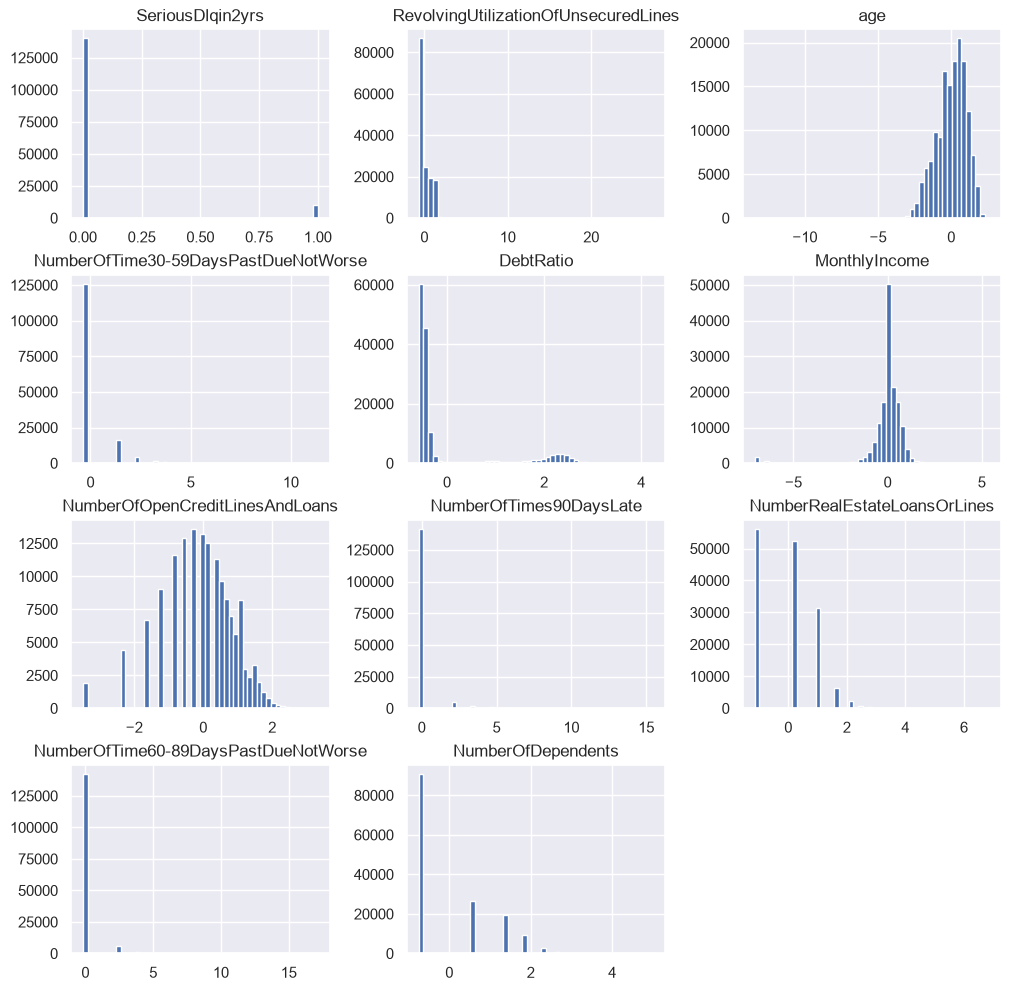

In [125]:
train_df.hist(bins=50, figsize=(12, 12));

In [80]:
preprocessing = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('log_trans', FunctionTransformer(np.log1p)),
    ('standardize', StandardScaler()),
])

In [96]:
cor_mat = train_df.corr()
cor_mat['SeriousDlqin2yrs'].abs().sort_values(ascending=False)

SeriousDlqin2yrs                        1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
age                                     0.115386
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfDependents                      0.046048
NumberOfOpenCreditLinesAndLoans         0.029669
MonthlyIncome                           0.019746
log_MonthlyIncome                       0.017929
DebtRatio                               0.007602
NumberRealEstateLoansOrLines            0.007038
RevolvingUtilizationOfUnsecuredLines    0.001802
Name: SeriousDlqin2yrs, dtype: float64

In [100]:
train_df['log_MonthlyIncome'] = np.log1p(train_df.MonthlyIncome)

AttributeError: 'numpy.ndarray' object has no attribute 'MonthlyIncome'

In [102]:
impute = SimpleImputer(strategy='median')
train_df = impute.fit_transform(train_df)